<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">📘 Batch, micro-batch a streaming - Northwind </h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">V nadväznosti na Seminár 8 - Zadanie 1a s MovieLens spracujeme údaje o objednávkach. Tentoraz si jednotlivé kroky naprogramujete samostatne od načítania CSV po porovnanie výsledkov.</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z kurzu si stiahnite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> (stĺpce <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">customerid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">employeeid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid</code>). Súbor uložte do rovnakého priečinka ako notebook. Knižnice a PostgreSQL už máte pripravené.</p>

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 1 – Načítanie a časová distribúcia objednávok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Načítajte súbor <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> a zmeňte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> na dátum. Zistite časový rozsah a počet objednávok podľa roku a mesiaca. Rozloženie zobrazte v grafe.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">pd.read_csv(..., parse_dates=["orderdate"])</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.year</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.to_period("M")</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">value_counts()</code>.</div>

Počet objednávok: 196
Najstaršia objednávka: 1996-07-04 00:00:00
Najnovšia objednávka: 1997-02-12 00:00:00


1996    152
1997     44
Name: orderdate, dtype: int64

1996-07    22
1996-08    25
1996-09    23
1996-10    26
1996-11    25
1996-12    31
1997-01    33
1997-02    11
Freq: M, Name: orderdate, dtype: int64

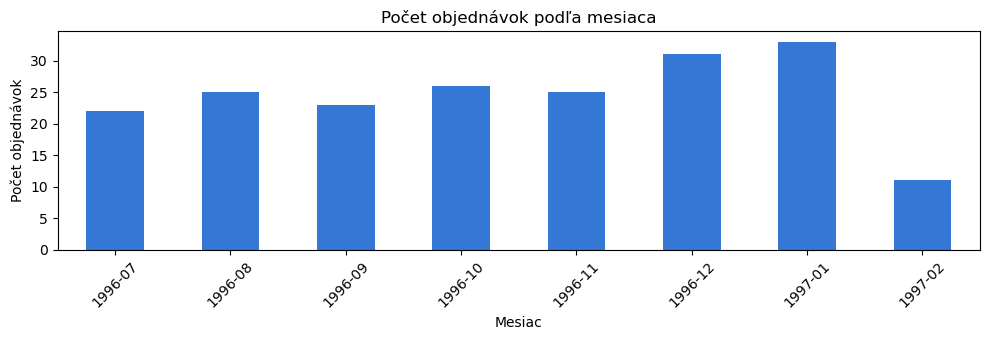

In [ ]:
# Moje riešenie
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
CSV_PATH = Path("cesta k week-08/orders.csv")
orders = pd.read_csv(CSV_PATH, parse_dates=["orderdate"])

print("Pocet objednavok:", len(orders))
print("Najstarsia objednavka:", orders["orderdate"].min())
print("Najnovsia objednavka:", orders["orderdate"].max())

orders_by_year = orders["orderdate"].dt.year.value_counts().sort_index()
orders_by_month = orders["orderdate"].dt.to_period("M").value_counts().sort_index()

display(orders_by_year)
display(orders_by_month)

ax = orders_by_month.plot(kind="bar", color="#3577d4", figsize=(10,3.5))
ax.set(title="Pocet objednavok podla mesiaca", xlabel="Mesiac", ylabel="Pocet objednavok")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 2 – Historické a novšie objednávky</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Podľa časového rozloženia zvoľte <strong>hranice 1. januára 1997</strong>. Staršie objednávky budú historický batch, objednávky od tohto dátumu využijeme na simuláciu príchodu udalostí.</p>
<ul style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.7; margin-top: 6px; padding-left: 24px;"><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">historical_orders</code> budú objednávky pred hranicou,</li><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">new_orders</code> naopak objednávky od hranice (vrátane),</li><li style="margin-bottom: 5px;">overte, že obe skupiny spolu obsahujú všetky objednávky.</li></ul>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong>Upozornenie: </strong> „Novšie“ objednávky sú stále <strong>historické záznamy</strong>. V nasledujúcich úlohách budeme ich príchod len simulovať.</div>

In [ ]:
# Moje riešenie
CUTOFF = pd.Timestamp("1997-01-01")

historical_orders = orders[orders["orderdate"] < CUTOFF].copy()
new_orders = orders[orders["orderdate"]>= CUTOFF].copy()

print("Historické objednávky:", len(historical_orders))
print("Novšie objednávky:", len(new_orders))
assert len(historical_orders) + len(new_orders) == len(orders)

Historické objednávky: 152
Novšie objednávky: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 3 – Raw ingestion do PostgreSQL</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte databázu <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">Northwind</code>, tabuľku <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> s primárnym kľúčom <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code> a nahrajte všetky záznamy z CSV. Predpokladáme, že PostgreSQL a balíky už fungujú inštaláciu ani test verzie preto nemusíte riešiť.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> najskôr sa pripojte do databázy <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">postgres</code>, vytvorte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders_practice</code> s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">AUTOCOMMIT</code>, potom zmeňte pripojenie. Na opakovateľný import použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">DROP TABLE IF EXISTS</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">to_sql(..., if_exists="append", index=False)</code>.</div>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong> Upozornenie:</strong> Pri opakovanom spustení sa obsah tabuľky <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> vymaže a znovu nahrá. Nepoužívajte názov databázy, ktorá už obsahuje vaše vlastné dáta.</div>

In [ ]:
# Moje riešenie
from sqlalchemy import create, engine, text

with engine.begin() as conn:
    conn.execute(text("DROP TABLE IF EXIST orders"))

    conn.execute(text("""
        CREATE TABLE orders (
        orderid INT PRIMARY KEY,
        customerid INT,
        employeeid INT, 
        orderdate TIMESTAMP,
        shipperid INT
        )
    """))

orders to sql(
    "orders",
    engine,
    if exists="append",
    index=false,
    chunksize=1000
)

print("Tabuľka orders bola vytvorená a naplnená.")


Tabuľka orders bola vytvorená a naplnená.


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 4 – Batch processing</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z historických objednávok vypočítajte <strong>počet objednávok</strong>, <strong>počet zákazníkov</strong> a <strong>percento objednávok s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid = 3</code></strong>. Výsledok získame jednorazovo za celú historickú skupinu.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Percento vypočítate ako <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(počet objednávok dopravcu 3 / počet všetkých objednávok) * 100</code>. Výraz <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(df["shipperid"] == 3).sum()</code> spočíta vyhovujúce riadky.</div>

In [ ]:
# Moje riešenie
historical_count = len(historical_orders)
historical_customers = historical_orders["customerid"].unique()
historical_shipper3_pct = (historical_orders["shipperid"].eq(1).mean()*100)
print("Objednávok:", historical_count)
print("Zákazníkov:",historical_customers)
print("Dopravca 3 (%):", round(historical_shipper3_pct,2))


Objednávok: 152
Zákazníkov: 66
Dopravca 3 (%): 38.16


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 5 – Spoločná vzorka pre tri prístupy</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na porovnanie musí každý prístup dostať <strong>rovnaké objednávky v rovnakom poradí</strong>. Z PostgreSQL vyberte novšie objednávky a zoraďte ich podľa <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">text()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">engine.connect()</code> a pomenované parametre SQL <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:cutoff</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:limit</code>. V tomto datasete je po hranici 44 objednávok, preto postačuje <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">SAMPLE_SIZE = 44</code>.</div>

In [ ]:
# Moj riešenie
SAMPLE_SIZE = 44

with engine.connect() as conn:
    event_sample = pd.read_sql(
        text("""
            SELECT orderid, customerid, employeeid, orderdate ,shipperid
            FROM orders
            WHERE orderdate >= :cutoff
            ORDER BY orderdate, orderid
            LIMIT :limit
        """),
        conn,
        params=(
            "cutoff":CUTOFF.to.pydatetime(),
            "limit": SAMPLE_SIZE
        ),
        parse_dates=["orderdate"]
    )

if event_sample.empty:
    raise ValueError("Ziadne objednavky po hranici CUTOFF.")

print("Objednávok v simulácii:", len(event_sample))


Objednávok v simulácii: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 6 – Simulácia micro-batchingu a streamingu</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Historické objednávky budeme prehrávať postupne. <strong>Streaming</strong> aktualizuje podiel dopravcu 3 po každej objednávke, <strong>micro-batch</strong> po uzavretí krátkeho časového okna. Batch poskytne výsledok až po príchode celej vzorky.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Pre tento malý dataset nastavíme <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">EVENT_DELAY_SEC = 0.04</code> (40 ms medzi objednávkami) a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">MICRO_WINDOW_SEC = 0.30</code> (približne 300 ms na dávku). Skutočné časy závisia od výkonu počítača.</div>

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok A – Nastavenia a priebežný stav</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Pripravte časové parametre, počítadlá a zoznamy na zaznamenávanie priebežných výsledkov. Pri micro-batchingu potrebujeme navyše premenné pre neuzavretú dávku.</p>

In [ ]:
# Moje riešenie
import time
EVENT_DELAY_SEC = 0.04
MICRO_WINDOW_SEC = 0.30

#STREAMING - stav a body grafu
stream_count, stream_shipper3 = 0,0
stream_updates= []

#MICRO-BATCH - spracovany stav, cakajuca davka a body grafu
micro_count, micro_shipper3 = 0,0
micro_pending_count, micro_pending_shipper3 = 0,0
micro_updates = []

start_time = time.perf_counter()
last_flush = start_time


<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok B – Spracovanie udalostí</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Prejdite objednávky postupne. Pri streamingu priebežne zapisujte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(čas, počet, percento)</code>. Pri micro-batchingu spracujte nazbierané objednávky až po uplynutí okna.</p>

In [ ]:
# Moje riešenie
for event in event_sample.itertuples(index=False):
    time.sleep(EVENT_DELAY_SEC)
    now = time.perf_counter()
    is_shipper3 = int(event.shipperi == 3)

    #STREAMING - aktualizacia po kazdej objednavke
    stream_count += 1
    stream_shipper3 += is_shipper3
    stream_updates.append((now - start_time, stream_count, 100 * stream_shipper3 / stream_count))

    #MICRO-BATCH najprv udaje zhromazdime
    micro_pending_count += 1
    micro_pending_shipper3 += is_shipper3
    if now - last_flush >= MICRO_WINDOW_SEC:
        micro_count += micro_pending_count
        micro_shipper3 += micro_pending_shipper3
        micro_updates.append((now - start_time, micro_count, 100 * micro_shipper3 / micro_count))
        micro_pending_count, micro_pending_shipper3 = 0,0
        last_flush = now


<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok C – Posledná dávka a batch</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Nezabudnite spracovať poslednú nedokončenú micro-batch dávku. Nakoniec vypočítajte jednorazový batch výsledok pre tú istú vzorku a overte rovnosť výsledných percent.</p>

In [ ]:
# Moje riešenie
import math

if micro_pending_count:
    micro_count += micro_pending_count
    micro_shipper3 += micro_pending_shipper3
    micro_updates.append((time.perf_counter() . start_time, micro_count, 100 * micro_shipper3 / micro_count))

batch_count = len(event_sample)
batch_pct = 100 * event_sample["shipperid"].eq(3).mean()
batch_ready_sec = time.perf_counter() - start_time
micro_pct = 100 * micro_shipper3 / micro_count
stream_pct = 100 * stream_shipper3 /stream_count

assert batch_count == micro_count == stream_count
assert math.isclose(batch_pct, micro_pct, abs_tol=1e-9)
assert math.isclose(batch_pct, stream_pct, abs_tol=1e-9)
print("Počet objednávok:",batch_count)
print("Batch (%):",round(batch_pct, 2))
print("Micro-batch (%):",round(micro_pct, 2))
print("Streaming (%):",round(stream_pct, 2))


Počet objednávok: 44
Batch (%): 22.73
Micro-batch (%): 22.73
Streaming (%): 22.73


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 7 – Grafy priebežných výsledkov</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte <strong>tri samostatné grafy</strong> pod sebou. V prvom zobrazte jednorazový batch bod, v druhom schodovitý priebeh micro-batchingu a v treťom streamingovú krivku. Použite spoločné osi, aby boli percentá porovnateľné.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plt.subplots(3, 1, sharex=True, sharey=True)</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">scatter()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">step(where="post")</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plot()</code>.</div>

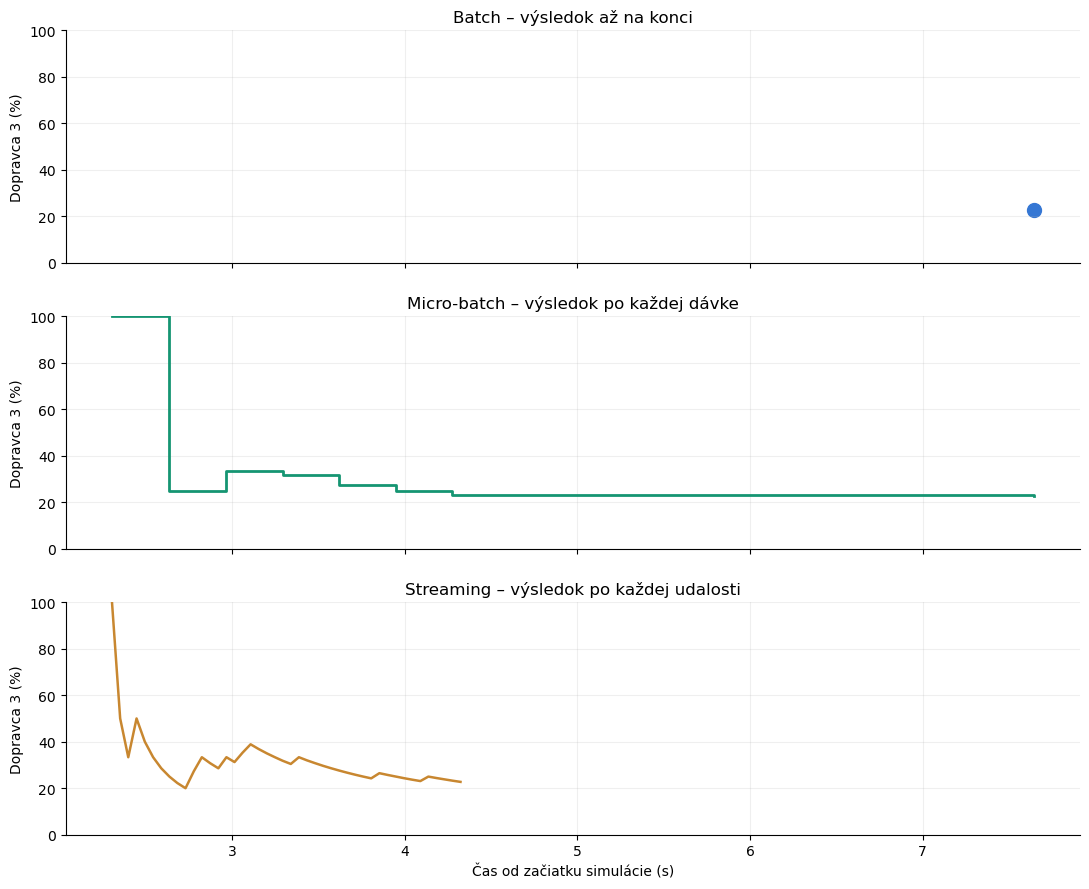

In [ ]:
# Moje riešenie
fig, axes = plt.subplots(3, 1, figsize=[11, 9], sharex=True, sharey=True)
axes[0].scatter([batch_ready_sec],[batch_pct], color="#3577d4",s=100)
axes[0].set_title("Batch - vysledok az na konci")

axes[1].step([x[0] for x in micro_updates],[x[2] for x in micro_updates], where="post", color="#159572", linewidth=2)
axes[1].set_title("Micro_batch - vysledok po kazdej davke")

axes[2].plot([x[0] for x in stream_updates],[x[2] for x in stream_updates], where="post", color="#c88730", linewidth=1.8)
axes[2].set_title("Streaming - vysledok po kazdej udalosti")

for ax in axes:
    ax.set_ylabel("Dopravca 3 (%)")
    ax.grid(alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim(0,100)
axes[2].set_xlabel("Cas od zaciatku simulacie (s)")
plt.tight_layout(h_pad=1.7)
plt.show()


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 8 – Frekvencia aktualizácií a prvý výsledok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na troch grafoch znázornite, koľkokrát sa priebežný výsledok aktualizoval. Potom vytvorte jednoduchú tabuľku, ktorá porovná <strong>čas prvého výsledku</strong>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Pri počte aktualizácií nie je vhodné zdieľať os Y: batch má jeden výsledok, streaming jeden po každej udalosti. Os X zdieľajte.</div>

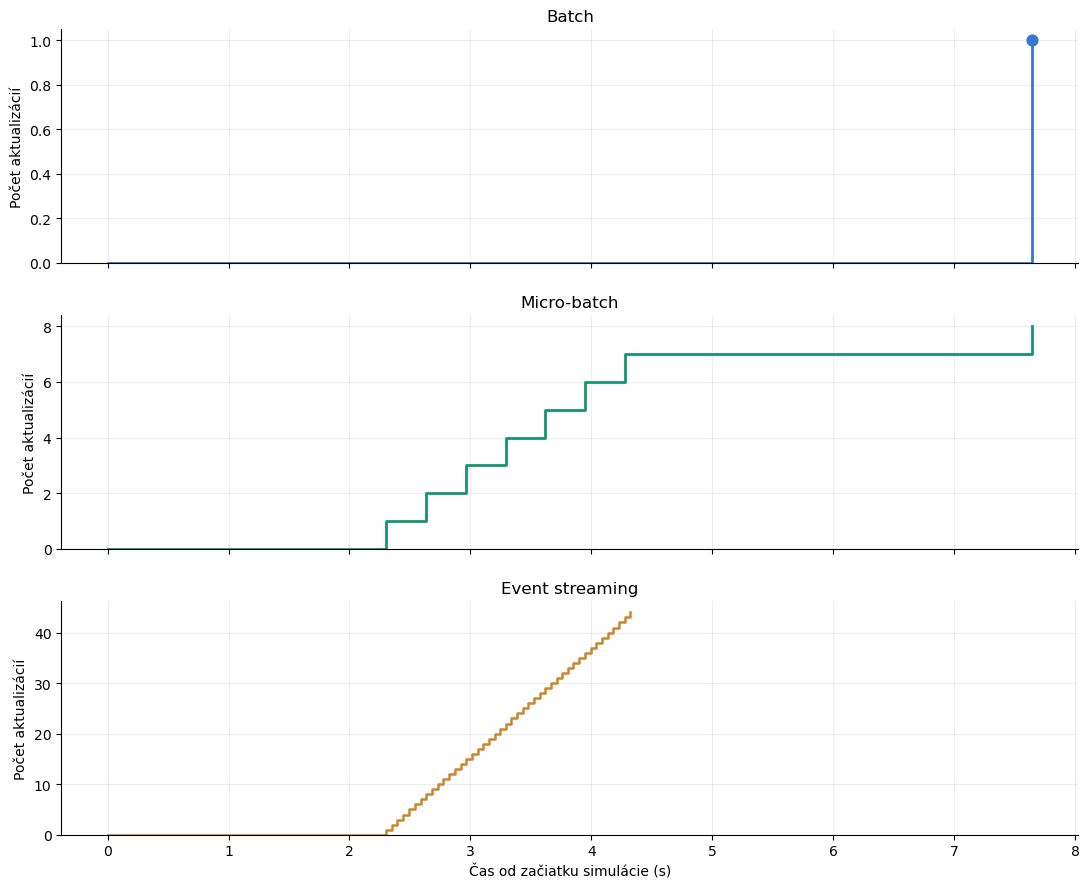

        Prístup Prvý výsledok (s)
          Batch             7.645
    Micro-batch             2.303
Event streaming             2.303


In [ ]:
# Moje riešenie
fig, axes = plt.subplots(3, 1, figsize=[11, 9], sharex=True)
axes[0].step([0,batch_ready_sec], [0, 1], where="post", color="#3577d4",linewidth=2)
axes[0].scatter([batch_ready_sec],[1], color="#3577d4", s=60, zorder=5)
axes[0].set_title("Batch")

axes[1].step([0] + [x[0] for x in micro_updates],[0] + list(range(1, len(micro_updates) + 1)), where="post", color="#159572", linewidth=2)
axes[1].set_title("Micro_batch")

axes[2].step([0] + [x[0] for x in stream_updates],[0] + list(range(1, len(stream_updates) + 1), where="post", color="#c88730", linewidth=1.8)
axes[2].set_title("Event streaming")

for ax in axes:
    ax.set_ylabel("Pocet aktualizacii")
    ax.grid(alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim(bottom=0)
axes[2].set_xlabel("Cas od zaciatku simulacie (s)")
plt.tight_layout(h_pad=1.7)
plt.show()

results = pd.DataFrame({
    "Pristup":["Batch", "Micro_batch", "Event streaming"],"Prvy vysledok (s)": [batch_ready_sec, micro_updates[0][0], stream_updates[0][0]])
})
print(results.to_string(index=False, formatters=["Prvy vysledok (s)": "{.3f}".format]))


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">
  📘 Kontrola Git repozitára po 8. týždni
</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Po dokončení všetkých úloh z 8. týždňa skontrolujte, či máte vo svojom Git
  repozitári vytvorenú samostatnú vetvu
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  a či sa v nej nachádza vypracovaný notebook vytvorený počas cvičenia.
</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Obsah vetvy
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  by mal mať približne nasledujúcu štruktúru:
</p>
<pre style="background: #f9fafb; color: #111827; padding: 14px; border-radius: 7px; overflow: auto; font-size: 13px; line-height: 1.7; font-family: ui-monospace, SFMono-Regular, Menlo, monospace;">week-08
│
├── ratings.csv
├── orders.csv
│
├── batch_streaming.ipynb
└── batch_streaming_orders.ipynb
</pre>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #eab308; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">
  ⚠️ <strong>Kontrola GitHubu:</strong> Skontrolujte, či sa všetky uvedené súbory
  nachádzajú aj vo vzdialenom repozitári na GitHube. Ak ich vidíte iba lokálne
  vo VS Code, zmeny ešte neboli úspešne odoslané pomocou
  <strong>commit</strong> a <strong>push</strong>.
</div>